In [64]:
import polars as pl
import matplotlib.pyplot as plt
import matplotlib as mpl
import altair as alt
#import pandas as pd
import numpy as np
import matplotlib.font_manager as fmx


import glob
import os
import sys
import math

mpl.rcParams.update({
    "pdf.fonttype": 42,           # TrueType = editable text
    "font.family": "Arial", # or Arial, Helvetica
    "text.usetex": False          # Absolutely must be False
})

In [66]:
#input input file, output dir and define cd55 ENSEMBL Gene ID
INPUT_FILE = "/Users/p.coli/Desktop/tximport_quant/0A_KALLISTO QUANT V1-3/V3_ensembl_kallisto_quant/03_filtered/filtered_tpm.csv"
OUTPUT_DIR = "/Users/p.coli/Desktop/tximport_quant/0A_KALLISTO QUANT V1-3/V3_ensembl_kallisto_quant/04_TPM_analysis/"
CD55_ID = "ENSG00000196352.18"

In [68]:
#import tpm.csv, relable GENEID column, and drop numberical ID artifact from R
tpm_df = pl.read_csv(INPUT_FILE)
tpm_df=tpm_df.drop(pl.col(tpm_df.columns[0]))
tpm_df= tpm_df.rename({tpm_df.columns[0]: "GENEID"})

#tpm_df.head(5)

In [62]:
#make a new df by taking the average of rep1 and rep2, add 1, log base 2
log_ave_df = tpm_df
for i in range(1, len(tpm_df.columns),2):
    name = tpm_df.columns[i][:-1]
    log_ave_df = log_ave_df.with_columns(
        (((pl.col(name + "1") + pl.col(name +"2"))/2)+1)
        .log(base=2)
        .alias(name + "Log2_average_+1")                                   
    )

log_ave_df = log_ave_df.select([col for col in log_ave_df.columns if 'average' in col.lower() or col == "GENEID"])

#log_ave_df.head(5)

In [48]:
#make a new df with a color column to uniquely identify CD55
plot_df = log_ave_df.with_columns(
    pl.when(pl.col("GENEID") == CD55_ID)
    .then(pl.lit("red"))
    .otherwise(pl.lit('gray'))
    .alias('color')
)
#plot_df.filter(pl.col("color") == "red") #quick test to see if code worked

In [9]:
editor_dict = {"dCas9":[1,2], "CRISPRtune": [5,6], "CRISPRi":[3,4]}

In [108]:
CD55_list =plot_df.filter(pl.col("GENEID") == CD55_ID).rows()
CD55_list=list(CD55_list[0])
CD55_list[editor_dict["dCas9"][1]]

6.371109647328428

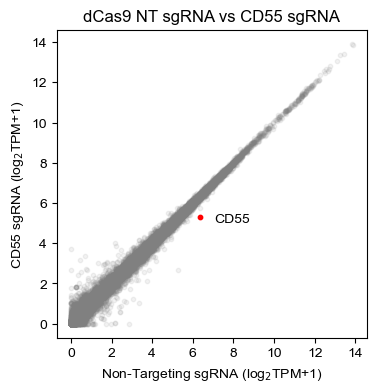

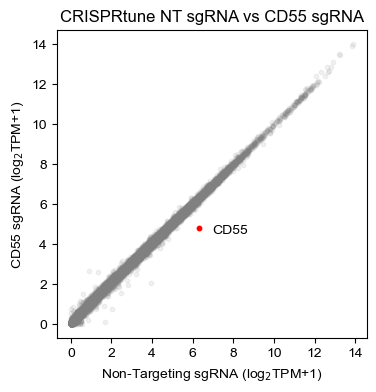

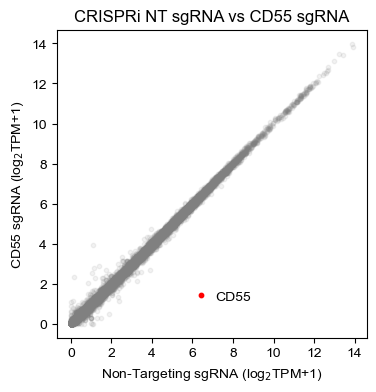

In [110]:
fig_dict ={}
ticks = np.arange(0, 16, 2)
for key in editor_dict.keys():
    fig, ax = plt.subplots(1, 1, figsize=(4, 4))
    for (c,), g in plot_df.group_by("color"):
        if c == "red":
            alpha = 1
            zorder = 10
        else:
            alpha = 0.1
            zorder = 5
        ax.scatter(
            g[plot_df.columns[editor_dict[key][1]]],
            g[plot_df.columns[editor_dict[key][0]]], 
            c=c, 
            alpha=alpha, 
            zorder=zorder, 
            s=10, 
            rasterized=True,
        )
        
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)

    ax.set_xlabel("Non-Targeting sgRNA (log$_2$TPM+1)")
    ax.set_ylabel("CD55 sgRNA (log$_2$TPM+1)")
    ax.annotate("CD55", (CD55_list[editor_dict[key][1]],CD55_list[editor_dict[key][0]]),textcoords="offset points", xytext=(10, -4),)
    ax.set_title(f"{key} NT sgRNA vs CD55 sgRNA", fontsize=12, color="black")
    plt.rcParams['font.family'] = 'Arial'

    
    fig_dict.update({key:fig})
    
    fig.savefig(OUTPUT_DIR + "png/" +f"V3_{key}_NT_sgRNA_vs_CD55_sgRNA.png", format="png", dpi = 500)
    fig.savefig(OUTPUT_DIR + "svg/" +f"V3_{key}_NT_sgRNA_vs_CD55_sgRNA.svg", format="svg", dpi = 300)


In [72]:
position_list=[]
experiment_list = []
for key in editor_dict.keys():
    for i in [1,0]:
        position_list.append(editor_dict[key][i])
        experiment_list.append(key + ("_NT" if i==1 else "_CD55"))
#print(position_list)
print(experiment_list)
#note: order = dCas9NT, dCas9CD55, CRISPRtuneNT, CRISPRtuneCD55, CRISPRiNT, CRISPRiCD55

['dCas9_NT', 'dCas9_CD55', 'CRISPRtune_NT', 'CRISPRtune_CD55', 'CRISPRi_NT', 'CRISPRi_CD55']


In [73]:
ave_df = tpm_df
for i in range(1, len(tpm_df.columns),2):
    name = tpm_df.columns[i][:-1]
    ave_df = ave_df.with_columns(
        ((pl.col(name + "1") + pl.col(name +"2"))/2)
        .alias(name + "_average")                                   
    )

ave_df = ave_df.select([col for col in ave_df.columns if 'average' in col.lower() or col == "GENEID"])
ave_CD55 = list(ave_df.filter(pl.col("GENEID") == CD55_ID).rows()[0])

sorted_ave_CD55 = []
for i in position_list:
    sorted_ave_CD55.append(ave_CD55[i])

In [77]:
error_df = tpm_df
for i in range(1, len(tpm_df.columns),2):
    name = tpm_df.columns[i][:-1]
    error_df = error_df.with_columns(
        (abs((pl.col(name + "1") - pl.col(name +"2"))/2))
        .alias(name + "_error")                                   
    )

error_df = error_df.select([col for col in error_df.columns if 'error' in col.lower() or col == "GENEID"])
error_CD55 = list(error_df.filter(pl.col("GENEID") == CD55_ID).rows()[0])

sorted_error_CD55 = []
for i in position_list:
    sorted_error_CD55.append(error_CD55[i])

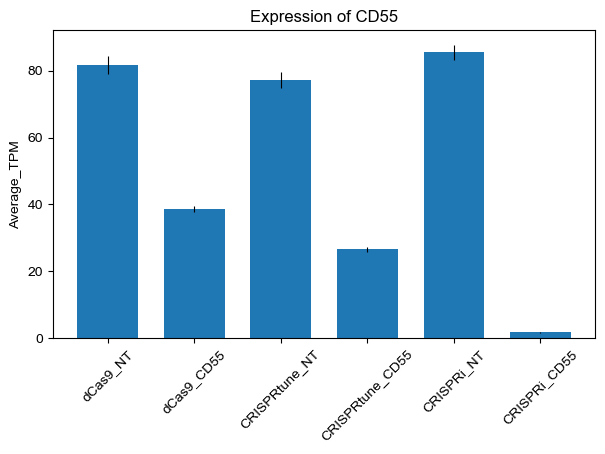

In [93]:
bar_fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(
    experiment_list,
    sorted_ave_CD55,
    yerr=sorted_error_CD55,
    width=0.7,
    error_kw=dict(linewidth=0.8),
)
ax.set_ylabel("Average_TPM")
ax.set_title("Expression of CD55")
plt.xticks(rotation=45)
bar_fig.savefig(OUTPUT_DIR + "png/" +"CD55_expression_barplot.png", format="png", dpi = 500)
bar_fig.savefig(OUTPUT_DIR + "svg/" +"CD55_expression_barplot.svg", format="svg", dpi = 300)

In [183]:
sorted_ave_CD55

[81.77422238638579,
 38.5573145685039,
 77.18677047219384,
 26.64207124075505,
 85.4733581995745,
 1.7420491973436398]

In [163]:
fold_change = []
for i in range(0, 6, 2):
    fold_change.append(sorted_ave_CD55[i]/sorted_ave_CD55[i+1])

In [167]:
#np.log10(np.array(fold_change))

In [169]:
fold_change

[2.1208484901379583, 2.8971760406570524, 49.06483601605993]